# Laboratorio #4 · Análisis exploratorio de Chinook
**Universidad Técnica Nacional · Minería de Datos · ISW-911**

**Integrantes:**
- Jose Andrés Miranda Arias
- Jose Felipe Carrera Araya
- Gerald Josue Gonzalez Granados
- Elías Josué Salas Méndez
- Rachel Barquero Varela

**Unidad de observación:** una pista del catálogo (audio o video). Se unen Track,
Album, Artist, Genre y MediaType mediante sus claves, sin duplicar pistas.

**Alcance autorizado:** la guía solicita datos abiertos de Costa Rica. Se utiliza
Chinook por autorización del profesor, según confirmó Gerald el 19/11/2026.
Chinook es una base de ejemplo, no un registro de la población costarricense.

**Objetivo:** describir calidad, distribución y relaciones de las variables del
catálogo; preparar predictores para estimar la duración de una pista.
No se modifica RDS, los CSV originales ni los jobs del proyecto.

Ejecutar todas las celdas en orden (Jupyter o Google Colab). Se necesita Internet
para descargar los CSV públicos de GitHub. Los resultados se guardan en el
directorio de ejecución: `data_process.csv`, `resultados/` y `fuentes/`.

## 1. Herramientas
Instalar una sola vez en el entorno seleccionado, si hace falta:
`%pip install pandas numpy matplotlib seaborn scikit-learn`

La celda de instalación queda como texto para no modificar el entorno al ejecutar
el análisis. Las versiones utilizadas están en `requirements.txt`.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import Request, urlopen
import hashlib
import json
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder

SALIDA = Path.cwd()
FIGURAS = SALIDA / 'resultados'
FUENTES = SALIDA / 'fuentes'
FIGURAS.mkdir(exist_ok=True)
FUENTES.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', palette='colorblind', font_scale=1.0)
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 120)
print('Python:', platform.python_version(), '| pandas:', pd.__version__)

def mostrar_figura(nombre):
    """Conserva el gráfico como evidencia y lo muestra dentro del notebook."""
    plt.tight_layout()
    plt.savefig(FIGURAS / nombre, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

Python: 3.12.14 | pandas: 3.1.1


## 2–3. Lectura desde GitHub y trazabilidad
Se fija el commit para reproducir exactamente la misma versión del dataset.
La lectura es HTTP desde GitHub; las copias en `fuentes/` son evidencia de esa
descarga y no sustituyen silenciosamente una descarga fallida.
No se usan credenciales de AWS ni de GitHub.

In [2]:
COMMIT = 'fcc25f0482b8186461312ac71c1c1f1805840309'
BASE = f'https://raw.githubusercontent.com/Gerald-JGG/invacom-data-warehouse/{COMMIT}/chinook_digital_store'
tablas = {}
procedencia = []
for nombre in ['Track', 'Album', 'Artist', 'Genre', 'MediaType']:
    url = f'{BASE}/{nombre}.csv'
    request = Request(url, headers={'User-Agent': 'UTN-Laboratorio4'})
    with urlopen(request, timeout=60) as respuesta:
        contenido = respuesta.read()
    (FUENTES / f'{nombre}.csv').write_bytes(contenido)
    tablas[nombre] = pd.read_csv(BytesIO(contenido))
    procedencia.append({'tabla': nombre, 'url': url, 'filas': len(tablas[nombre]),
                        'sha256': hashlib.sha256(contenido).hexdigest()})
display(pd.DataFrame(procedencia)[['tabla', 'filas', 'url']])
(FIGURAS / 'procedencia.json').write_text(
    json.dumps(procedencia, ensure_ascii=False, indent=2), encoding='utf-8')

,tabla,filas,url
0,Track,3503,https://raw.githubusercontent.com/Gerald-JGG/i...
1,Album,347,https://raw.githubusercontent.com/Gerald-JGG/i...
2,Artist,275,https://raw.githubusercontent.com/Gerald-JGG/i...
3,Genre,25,https://raw.githubusercontent.com/Gerald-JGG/i...
4,MediaType,5,https://raw.githubusercontent.com/Gerald-JGG/i...


1435

## 4. Integración y características básicas
Las uniones son muchos-a-uno, validadas por pandas. El catálogo completo incluye
videos; se conserva ese contexto para interpretar duración y tamaño.
Se revisan forma, primeras/últimas filas, muestra reproducible, tipos,
estadísticos y unicidad. Los identificadores no son magnitudes para correlación.

In [3]:
datos = (tablas['Track']
    .merge(tablas['Album'].rename(columns={'Title': 'Album'}),
           on='AlbumId', how='left', validate='many_to_one')
    .merge(tablas['Artist'].rename(columns={'Name': 'Artist'}),
           on='ArtistId', how='left', validate='many_to_one')
    .merge(tablas['Genre'].rename(columns={'Name': 'Genre'}),
           on='GenreId', how='left', validate='many_to_one')
    .merge(tablas['MediaType'].rename(columns={'Name': 'MediaType'}),
           on='MediaTypeId', how='left', validate='many_to_one'))
assert len(datos) == len(tablas['Track'])
assert datos['TrackId'].is_unique
assert datos[['Album', 'Artist', 'Genre', 'MediaType']].notna().all().all()
print('Filas y columnas:', datos.shape)
datos.info()
display(datos.head(), datos.tail(), datos.sample(5, random_state=42))
display(datos.describe(include='all').T)
print('Filas idénticas repetidas:', int(datos.duplicated().sum()))
print('Identificadores de pista repetidos:', int(datos['TrackId'].duplicated().sum()))

Filas y columnas: (3503, 14)
<class 'pandas.DataFrame'>
RangeIndex: 3503 entries, 0 to 3502
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   TrackId       3503 non-null   int64  
 1   Name          3503 non-null   str    
 2   AlbumId       3503 non-null   int64  
 3   MediaTypeId   3503 non-null   int64  
 4   GenreId       3503 non-null   int64  
 5   Composer      2525 non-null   str    
 6   Milliseconds  3503 non-null   int64  
 7   Bytes         3503 non-null   int64  
 8   UnitPrice     3503 non-null   float64
 9   Album         3503 non-null   str    
 10  ArtistId      3503 non-null   int64  
 11  Artist        3503 non-null   str    
 12  Genre         3503 non-null   str    
 13  MediaType     3503 non-null   str    
dtypes: float64(1), int64(7), str(6)
memory usage: 383.3 KB


,TrackId,Name,AlbumId,MediaTypeId,GenreId,Composer,Milliseconds,Bytes,UnitPrice,Album,ArtistId,Artist,Genre,MediaType
0,1,For Those About To Rock (We Salute You),1,1,1,"Angus Young, Malcolm Young, Brian Johnson",343719,11170334,0.99,For Those About To Rock We Salute You,1,AC/DC,Rock,MPEG audio file
1,2,Balls to the Wall,2,2,1,NaN,342562,5510424,0.99,Balls to the Wall,2,Accept,Rock,Protected AAC audio file
2,3,Fast As a Shark,3,2,1,"F. Baltes, S. Kaufman, U. Dirkscneider & W. Ho...",230619,3990994,0.99,Restless and Wild,2,Accept,Rock,Protected AAC audio file
3,4,Restless and Wild,3,2,1,"F. Baltes, R.A. Smith-Diesel, S. Kaufman, U. D...",252051,4331779,0.99,Restless and Wild,2,Accept,Rock,Protected AAC audio file
4,5,Princess of the Dawn,3,2,1,Deaffy & R.A. Smith-Diesel,375418,6290521,0.99,Restless and Wild,2,Accept,Rock,Protected AAC audio file


,TrackId,Name,AlbumId,MediaTypeId,GenreId,Composer,Milliseconds,Bytes,UnitPrice,Album,ArtistId,Artist,Genre,MediaType
3498,3499,Pini Di Roma (Pinien Von Rom) \ I Pini Della V...,343,2,24,NaN,286741,4718950,0.99,Respighi:Pines of Rome,226,Eugene Ormandy,Classical,Protected AAC audio file
3499,3500,"String Quartet No. 12 in C Minor, D. 703 ""Quar...",344,2,24,Franz Schubert,139200,2283131,0.99,Schubert: The Late String Quartets & String Qu...,272,Emerson String Quartet,Classical,Protected AAC audio file
3500,3501,"L'orfeo, Act 3, Sinfonia (Orchestra)",345,2,24,Claudio Monteverdi,66639,1189062,0.99,Monteverdi: L'Orfeo,273,"C. Monteverdi, Nigel Rogers - Chiaroscuro; Lon...",Classical,Protected AAC audio file
3501,3502,"Quintet for Horn, Violin, 2 Violas, and Cello ...",346,2,24,Wolfgang Amadeus Mozart,221331,3665114,0.99,Mozart: Chamber Music,274,Nash Ensemble,Classical,Protected AAC audio file
3502,3503,Koyaanisqatsi,347,2,10,Philip Glass,206005,3305164,0.99,Koyaanisqatsi (Soundtrack from the Motion Pict...,275,Philip Glass Ensemble,Soundtrack,Protected AAC audio file


,TrackId,Name,AlbumId,MediaTypeId,GenreId,Composer,Milliseconds,Bytes,UnitPrice,Album,ArtistId,Artist,Genre,MediaType
3150,3151,Seu Balancê,248,1,7,Paulinho Rezende/Toninho Geraes,219454,7311219,0.99,Ao Vivo [IMPORT],155,Zeca Pagodinho,Latin,MPEG audio file
315,316,Linha Do Equador,28,1,7,NaN,244715,8123466,0.99,Na Pista,20,Cláudio Zoli,Latin,MPEG audio file
2178,2179,Save You,180,1,1,Eddie Vedder/Jeff Ament/Matt Cameron/Mike McCr...,230112,7609110,0.99,Riot Act,118,Pearl Jam,Rock,MPEG audio file
2772,2773,Padre Cícero,223,1,7,NaN,139598,4581685,0.99,Serie Sem Limite (Disc 2),145,Tim Maia,Latin,MPEG audio file
430,431,The Invisible Man,36,1,1,Queen,238994,7920353,0.99,Greatest Hits II,51,Queen,Rock,MPEG audio file


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
TrackId,3503.0,NaN,NaN,NaN,1752.0,1011.373324,1.0,876.5,1752.0,2627.5,3503.0
Name,3503,3257,The Number Of The Beast,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AlbumId,3503.0,NaN,NaN,NaN,140.929489,81.775395,1.0,70.5,141.0,212.0,347.0
MediaTypeId,3503.0,NaN,NaN,NaN,1.208393,0.580443,1.0,1.0,1.0,1.0,5.0
GenreId,3503.0,NaN,NaN,NaN,5.725378,6.190204,1.0,1.0,3.0,7.0,25.0
Composer,2525,852,Steve Harris,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Milliseconds,3503.0,NaN,NaN,NaN,393599.212104,535005.435207,1071.0,207281.0,255634.0,321645.0,5286953.0
Bytes,3503.0,NaN,NaN,NaN,33510207.065373,105392533.664763,38747.0,6342566.0,8107896.0,10266789.5,1059546140.0
UnitPrice,3503.0,NaN,NaN,NaN,1.050805,0.239006,0.99,0.99,0.99,0.99,1.99
Album,3503,347,Greatest Hits,57,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Filas idénticas repetidas: 0
Identificadores de pista repetidos: 0


## 5. Nombres de columnas en español y diccionario
Se renombran encabezados; no se traducen títulos, artistas o categorías originales
para evitar alterar su significado. `precio_unitario` conserva la unidad monetaria
sin atribuir una moneda no especificada en los CSV.

In [4]:
nombres = {'TrackId': 'id_pista', 'Name': 'nombre_pista', 'AlbumId': 'id_album',
           'MediaTypeId': 'id_tipo_medio', 'GenreId': 'id_genero',
           'Composer': 'compositor', 'Milliseconds': 'duracion_ms',
           'Bytes': 'tamano_bytes', 'UnitPrice': 'precio_unitario',
           'Album': 'album', 'ArtistId': 'id_artista', 'Artist': 'artista',
           'Genre': 'genero', 'MediaType': 'tipo_medio'}
datos = datos.rename(columns=nombres)
diccionario = pd.DataFrame([
    {'columna_original': a, 'columna_espanol': b,
     'tipo_inicial': str(datos[b].dtype)} for a, b in nombres.items()])
display(diccionario)
diccionario.to_csv(FIGURAS / 'diccionario_columnas.csv', index=False, encoding='utf-8-sig')
# Los espacios externos o cadenas vacías se tratan antes del conteo de faltantes.
for columna in datos.select_dtypes(include=['object', 'string']).columns:
    datos[columna] = datos[columna].astype('string').str.strip().replace('', pd.NA)
original = datos.copy(deep=True)

,columna_original,columna_espanol,tipo_inicial
0,TrackId,id_pista,int64
1,Name,nombre_pista,str
2,AlbumId,id_album,int64
3,MediaTypeId,id_tipo_medio,int64
4,GenreId,id_genero,int64
5,Composer,compositor,str
6,Milliseconds,duracion_ms,int64
7,Bytes,tamano_bytes,int64
8,UnitPrice,precio_unitario,float64
9,Album,album,str


## 6. Valores nulos: evidencia antes de imputar
Un compositor ausente significa que no está informado. Asignar el compositor más
frecuente a otra canción inventaría autoría. Se usará `No informado` y se
conservará una bandera que permita reconocer los registros imputados.

,nulos,porcentaje
id_pista,0,0.000000
nombre_pista,0,0.000000
id_album,0,0.000000
id_tipo_medio,0,0.000000
id_genero,0,0.000000
compositor,978,27.918927
duracion_ms,0,0.000000
tamano_bytes,0,0.000000
precio_unitario,0,0.000000
album,0,0.000000


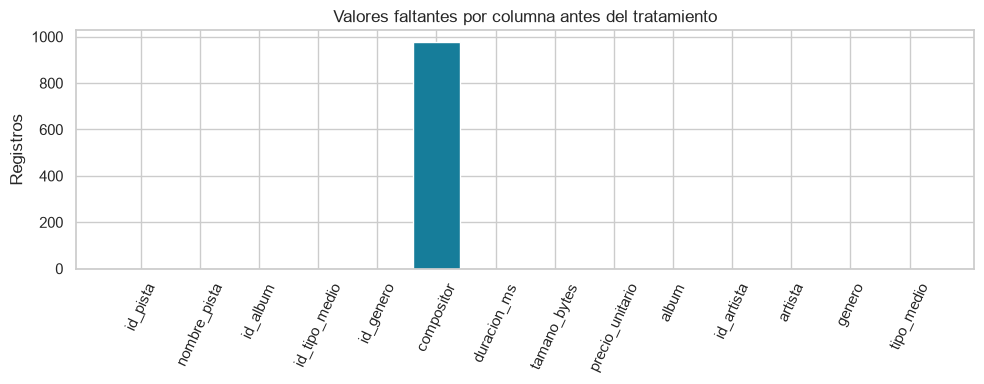

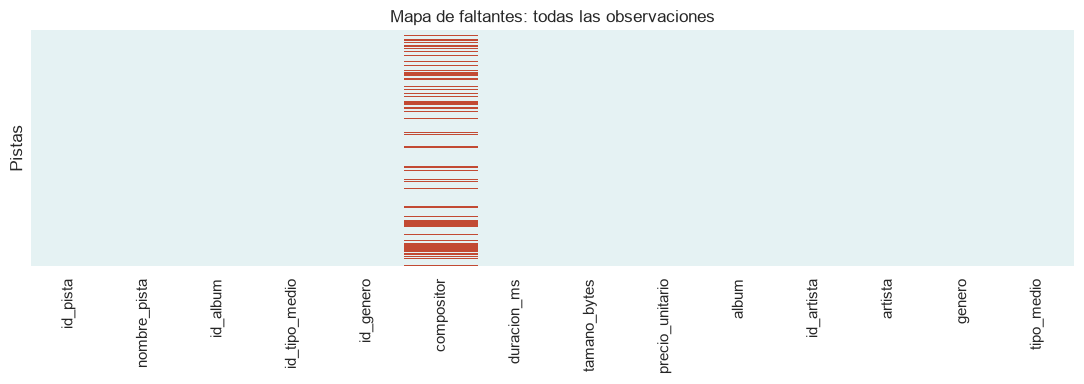

Se encontraron **978** compositores sin informar (**27.92%** de las pistas).

In [5]:
nulos = datos.isna().sum().rename('nulos').to_frame()
nulos['porcentaje'] = nulos['nulos'] / len(datos) * 100
display(nulos)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(nulos.index, nulos['nulos'], color='#167d9a')
ax.set(title='Valores faltantes por columna antes del tratamiento', ylabel='Registros')
ax.tick_params(axis='x', rotation=65)
mostrar_figura('01_nulos_antes.png')
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(datos.isna(), cbar=False, yticklabels=False, ax=ax, cmap=['#e5f2f3', '#c24a33'])
ax.set(title='Mapa de faltantes: todas las observaciones', ylabel='Pistas')
mostrar_figura('02_mapa_nulos.png')
display(Markdown(f"Se encontraron **{int(nulos.loc['compositor', 'nulos'])}** compositores "
    f"sin informar (**{nulos.loc['compositor', 'porcentaje']:.2f}%** de las pistas)."))

## 7. Valores atípicos y revisión de plausibilidad
Se usa la regla exploratoria IQR: límites Q1 − 1.5×IQR y Q3 + 1.5×IQR.
Una bandera IQR no demuestra un error. Con IQR=0 (posible en precios de catálogo),
los valores distintos del precio dominante requieren revisión, no sustitución.
Se comparan audio y video para evitar juzgar una película como canción de 3 minutos.

,variable,limite_inferior,limite_superior,IQR,atipicos
0,duracion_ms,35735.00,493191.00,114364.0,357
1,tamano_bytes,456230.75,16153124.75,3924223.5,343
2,precio_unitario,0.99,0.99,0.0,213


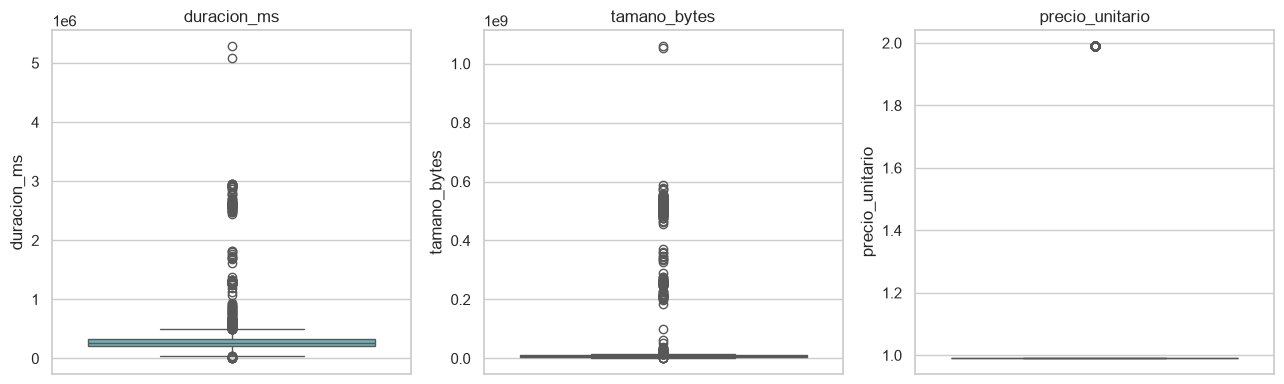

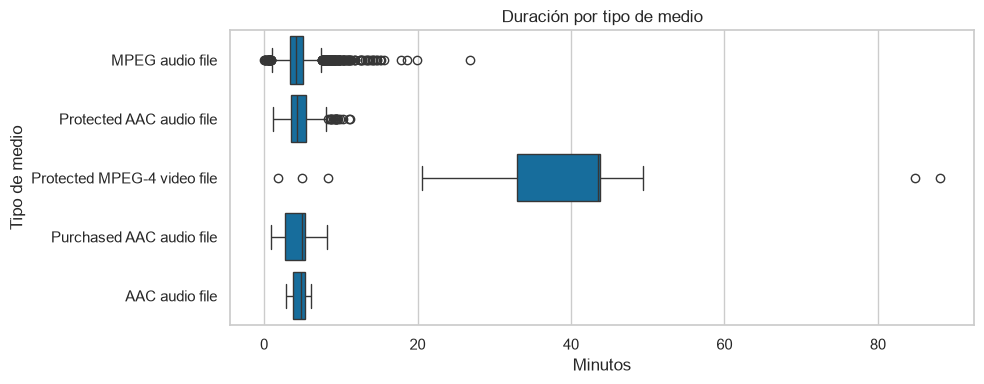

,id_pista,nombre_pista,tipo_medio,duracion_ms,tamano_bytes
2819,2820,Occupation / Precipice,Protected MPEG-4 video file,5286953,1054423946
3223,3224,Through a Looking Glass,Protected MPEG-4 video file,5088838,1059546140
3243,3244,"Greetings from Earth, Pt. 1",Protected MPEG-4 video file,2960293,536824558
3241,3242,The Man With Nine Lives,Protected MPEG-4 video file,2956998,577829804
3226,3227,"Battlestar Galactica, Pt. 2",Protected MPEG-4 video file,2956081,521387924
3225,3226,"Battlestar Galactica, Pt. 1",Protected MPEG-4 video file,2952702,541359437
3242,3243,Murder On the Rising Star,Protected MPEG-4 video file,2935894,551759986
3227,3228,"Battlestar Galactica, Pt. 3",Protected MPEG-4 video file,2927802,554509033


Duraciones no positivas: 0
Tamaños no positivos: 0
Precios negativos: 0


In [6]:
medidas = ['duracion_ms', 'tamano_bytes', 'precio_unitario']
def limites_iqr(serie):
    """Límites descriptivos; no altera ni borra datos."""
    q1, q3 = serie.dropna().quantile([0.25, 0.75])
    iqr = q3 - q1
    return float(q1 - 1.5 * iqr), float(q3 + 1.5 * iqr), float(iqr)

filas_atipicos = []
for col in medidas:
    inferior, superior, iqr = limites_iqr(datos[col])
    mascara = (datos[col] < inferior) | (datos[col] > superior)
    datos[f'atipico_{col}'] = mascara.astype('int8')
    filas_atipicos.append({'variable': col, 'limite_inferior': inferior,
                          'limite_superior': superior, 'IQR': iqr,
                          'atipicos': int(mascara.sum())})
tabla_atipicos = pd.DataFrame(filas_atipicos)
display(tabla_atipicos)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, medidas):
    sns.boxplot(y=datos[col], ax=ax, color='#69b7be')
    ax.set_title(col)
mostrar_figura('03_atipicos_boxplots.png')
fig, ax = plt.subplots(figsize=(10, 4))
comparacion = datos.assign(duracion_minutos=datos['duracion_ms'] / 60000)
sns.boxplot(data=comparacion, x='duracion_minutos', y='tipo_medio', ax=ax)
ax.set(title='Duración por tipo de medio', xlabel='Minutos', ylabel='Tipo de medio')
mostrar_figura('04_duracion_por_medio.png')
display(datos.nlargest(8, 'duracion_ms')[
    ['id_pista', 'nombre_pista', 'tipo_medio', 'duracion_ms', 'tamano_bytes']])
print('Duraciones no positivas:', int((datos['duracion_ms'] <= 0).sum()))
print('Tamaños no positivos:', int((datos['tamano_bytes'] <= 0).sum()))
print('Precios negativos:', int((datos['precio_unitario'] < 0).sum()))

## 8–9. Funciones de imputación y conversiones
Se conserva el catálogo: los extremos positivos son plausibles según tipo de
medio; no se recortan, eliminan ni reemplazan por una media. Para la asimetría
del tamaño se aplica `log1p` en la preparación numérica.

La función numérica aprende medianas **solo del subconjunto de entrenamiento**,
por tipo de medio y con respaldo global. Solo se aplica a faltantes o valores
físicamente inválidos, no a extremos IQR válidos. Si no existen, reporta cero
cambios. La variable objetivo no se imputa: una duración inválida requeriría
revisar el registro fuente. En este dataset se comprueba su validez.

La guía menciona imputar hallazgos de puntos 5 y 6; se documentan también los
atípicos del punto 7 para cubrir ambos problemas de calidad.

,variable,valores_imputados
0,tamano_bytes,0
1,precio_unitario,0


Compositores completados: 978


,tipo_final
id_pista,int64
nombre_pista,string
id_album,int64
id_tipo_medio,int64
id_genero,int64
compositor,string
duracion_ms,int64
tamano_bytes,int64
precio_unitario,float64
album,string


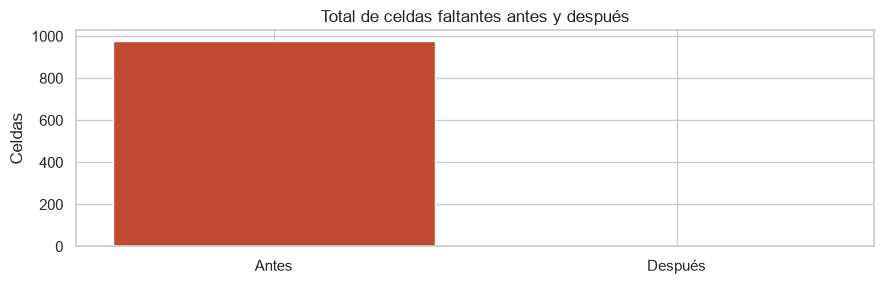

In [7]:
def imputar_texto(serie, etiqueta='No informado'):
    """No atribuye autores; marca explícitamente información desconocida."""
    return serie.astype('string').str.strip().replace('', pd.NA).fillna(etiqueta)

def imputar_numerica_por_grupo(serie, grupos, referencia, grupos_referencia,
                              cero_valido=False):
    """Usa medianas válidas de entrenamiento. Conserva los extremos positivos."""
    valida = referencia.ge(0) if cero_valido else referencia.gt(0)
    ref = referencia.where(valida)
    medianas = ref.groupby(grupos_referencia).median()
    global_mediana = ref.median()
    if pd.isna(global_mediana):
        raise ValueError('No hay valores válidos para aprender la imputación.')
    invalida = serie.isna() | (serie.lt(0) if cero_valido else serie.le(0))
    valores = grupos.map(medianas).fillna(global_mediana)
    return serie.where(~invalida, valores), int(invalida.sum())

datos['compositor_no_informado'] = datos['compositor'].isna().astype('int8')
datos['compositor'] = imputar_texto(datos['compositor'])
for col in ['nombre_pista', 'album', 'artista', 'genero', 'tipo_medio']:
    datos[col] = imputar_texto(datos[col])
ids = ['id_pista', 'id_album', 'id_artista', 'id_genero', 'id_tipo_medio']
for col in ids + ['duracion_ms', 'tamano_bytes']:
    datos[col] = pd.to_numeric(datos[col], errors='raise').astype('int64')
datos['precio_unitario'] = pd.to_numeric(datos['precio_unitario'], errors='raise').astype('float64')
assert datos['duracion_ms'].notna().all() and datos['duracion_ms'].gt(0).all()

# Separar por álbum evita que pistas del mismo álbum aparezcan en ambos grupos.
division = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_entrena, idx_prueba = next(division.split(datos, groups=datos['id_album']))
assert set(datos.iloc[idx_entrena]['id_album']).isdisjoint(datos.iloc[idx_prueba]['id_album'])
datos['particion'] = 'prueba'
datos.loc[idx_entrena, 'particion'] = 'entrenamiento'
imputaciones = []
for col in ['tamano_bytes', 'precio_unitario']:
    datos[col], cambios = imputar_numerica_por_grupo(
        datos[col], datos['tipo_medio'], datos.iloc[idx_entrena][col],
        datos.iloc[idx_entrena]['tipo_medio'], cero_valido=(col == 'precio_unitario'))
    imputaciones.append({'variable': col, 'valores_imputados': cambios})
datos['duracion_minutos'] = datos['duracion_ms'] / 60000
datos['tamano_mb'] = datos['tamano_bytes'] / 1_000_000
display(pd.DataFrame(imputaciones))
print('Compositores completados:', int(datos['compositor_no_informado'].sum()))
display(datos.dtypes.rename('tipo_final').to_frame())
assert not datos.isna().any().any()
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(['Antes', 'Después'], [int(original.isna().sum().sum()), int(datos.isna().sum().sum())],
       color=['#c24a33', '#167d9a'])
ax.set(title='Total de celdas faltantes antes y después', ylabel='Celdas')
mostrar_figura('05_nulos_despues.png')

## 10–11. Codificación y estandarización
`genero` y `tipo_medio` son nominales: one-hot evita inventar un orden numérico.
Se excluyen del modelo IDs, títulos, álbum, artista y compositor por su carácter
identificador o alta cardinalidad. Se conservan en el CSV para trazabilidad.

Se crean predictores con log1p(tamaño en MB) y precio, estandarizados con
StandardScaler (media 0 y desviación poblacional 1 en entrenamiento; una columna
constante tendría desviación 0). El objetivo conserva minutos interpretables.
El codificador y escalador se ajustan solo con entrenamiento; después transforman
todas las filas. El EDA completo es descriptivo, no una evaluación predictiva.

,log_tamano_mb_z,precio_unitario_z,genero_Alternative,genero_Alternative & Punk,genero_Blues,genero_Bossa Nova,genero_Classical,genero_Comedy,genero_Drama,genero_Electronica/Dance,genero_Heavy Metal,genero_Hip Hop/Rap,...,genero_Rock,genero_Rock And Roll,genero_Sci Fi & Fantasy,genero_Science Fiction,genero_Soundtrack,genero_TV Shows,genero_World,tipo_medio_AAC audio file,tipo_medio_MPEG audio file,tipo_medio_Protected AAC audio file,tipo_medio_Protected MPEG-4 video file,tipo_medio_Purchased AAC audio file
0,0.059783,-0.274117,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,1,0,0,0
1,-0.528161,-0.274117,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1,0,0
2,-0.777935,-0.274117,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1,0,0
3,-0.715861,-0.274117,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1,0,0
4,-0.421802,-0.274117,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1,0,0


,log_tamano_mb_z,precio_unitario_z
mean,4.226276e-17,5.071532e-16
std,1.000186e+00,1.000186e+00


La std de pandas usa ddof=1; StandardScaler utiliza ddof=0.
Desviación poblacional: {'log_tamano_mb_z': 0.9999999999999999, 'precio_unitario_z': 1.0}


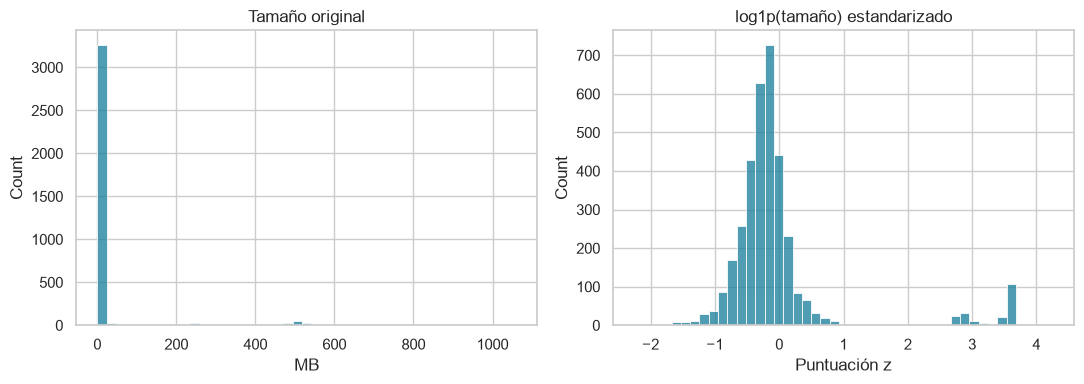

In [8]:
categoricas = ['genero', 'tipo_medio']
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.int8)
encoder.fit(datos.iloc[idx_entrena][categoricas])
codificadas = pd.DataFrame(encoder.transform(datos[categoricas]), index=datos.index,
    columns=encoder.get_feature_names_out(categoricas))
numericas_modelo = pd.DataFrame({
    'log_tamano_mb': np.log1p(datos['tamano_mb']),
    'precio_unitario': datos['precio_unitario']}, index=datos.index)
scaler = StandardScaler()
scaler.fit(numericas_modelo.iloc[idx_entrena])
estandarizadas = pd.DataFrame(scaler.transform(numericas_modelo), index=datos.index,
    columns=['log_tamano_mb_z', 'precio_unitario_z'])
X = pd.concat([estandarizadas, codificadas], axis=1)
y = datos['duracion_minutos'].copy()
assert np.isfinite(X.to_numpy()).all() and X.columns.is_unique
assert np.allclose(estandarizadas.iloc[idx_entrena].mean(), 0, atol=1e-10)
display(X.head())
display(estandarizadas.iloc[idx_entrena].agg(['mean', 'std']))
print('La std de pandas usa ddof=1; StandardScaler utiliza ddof=0.')
print('Desviación poblacional:', estandarizadas.iloc[idx_entrena].std(ddof=0).to_dict())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(datos['tamano_mb'], bins=45, ax=axes[0], color='#167d9a')
axes[0].set(title='Tamaño original', xlabel='MB')
sns.histplot(estandarizadas['log_tamano_mb_z'], bins=45, ax=axes[1], color='#167d9a')
axes[1].set(title='log1p(tamaño) estandarizado', xlabel='Puntuación z')
mostrar_figura('06_estandarizacion.png')

## 12. Correlación con evidencia gráfica
Se calculan Pearson (relación lineal) y Spearman (relación monótona) para duración,
tamaño y precio. Se excluyen IDs y códigos arbitrarios de categorías. No se
incluyen a la vez milisegundos/minutos o bytes/MB porque su correlación sería
trivial por conversión de unidades. La mezcla de audio/video puede confundir
la relación agregada; también se inspecciona por tipo de medio.

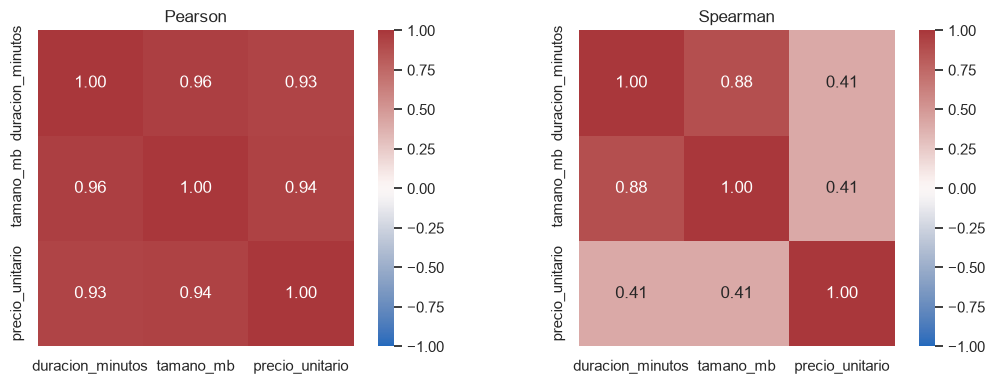

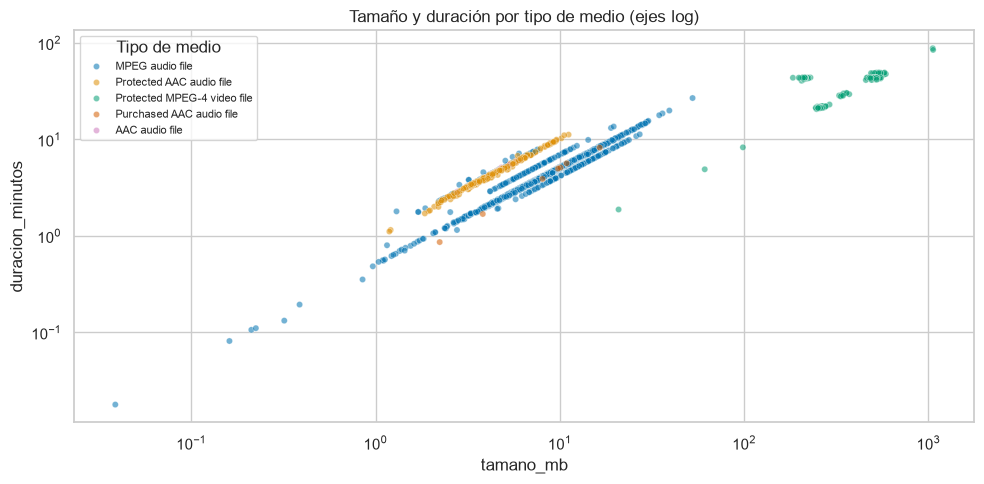

,tipo_medio,pistas,pearson_tamano_duracion
0,AAC audio file,11,0.998230
1,MPEG audio file,3034,0.963860
2,Protected AAC audio file,237,0.998031
3,Protected MPEG-4 video file,214,0.769058
4,Purchased AAC audio file,7,0.998758


Tamaño-duración: Pearson **0.960**; Spearman **0.880**. La asociación refleja en parte duración, formato y compresión; no demuestra causalidad.

In [9]:
variables_correlacion = ['duracion_minutos', 'tamano_mb', 'precio_unitario']
pearson = datos[variables_correlacion].corr(method='pearson')
spearman = datos[variables_correlacion].corr(method='spearman')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, matriz, titulo in zip(axes, [pearson, spearman], ['Pearson', 'Spearman']):
    sns.heatmap(matriz, annot=True, fmt='.2f', vmin=-1, vmax=1,
                cmap='vlag', square=True, ax=ax)
    ax.set_title(titulo)
mostrar_figura('07_correlaciones.png')
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=datos, x='tamano_mb', y='duracion_minutos', hue='tipo_medio',
                alpha=0.55, s=20, ax=ax)
ax.set(xscale='log', yscale='log', title='Tamaño y duración por tipo de medio (ejes log)')
ax.legend(title='Tipo de medio', fontsize=8)
mostrar_figura('08_tamano_duracion.png')
correlacion_grupo = []
for tipo, grupo in datos.groupby('tipo_medio'):
    correlacion_grupo.append({'tipo_medio': tipo, 'pistas': len(grupo),
        'pearson_tamano_duracion': grupo['tamano_mb'].corr(grupo['duracion_minutos'])})
display(pd.DataFrame(correlacion_grupo))
display(Markdown(
    f"Tamaño-duración: Pearson **{pearson.loc['tamano_mb', 'duracion_minutos']:.3f}**; "
    f"Spearman **{spearman.loc['tamano_mb', 'duracion_minutos']:.3f}**. "
    'La asociación refleja en parte duración, formato y compresión; no demuestra causalidad.'))

## 13. Variable dependiente y modelo candidato
**Problema propuesto:** estimar la duración en minutos de una pista cuando se
conocen tamaño del archivo, tipo de medio, género y precio. En un catálogo real
debe preferirse leer la duración del archivo si está disponible; este es un
ejercicio de regresión con la duración observada como etiqueta.

**Dependiente:** `duracion_minutos`, cuantitativa continua. **Predictores:** las
columnas de `X`. No se usa `duracion_ms` como predictor porque contiene exactamente
la respuesta en otra unidad (fuga de información).

**Candidato:** árbol de decisión de regresión con profundidad limitada, comparado
contra una predicción constante basada en la mediana de entrenamiento. Permite
relaciones no lineales y diferencias entre formatos. Un árbol no necesita
estandarización, pero se realiza para cumplir el laboratorio y facilitar la
comparación con una regresión lineal. La selección final depende de los modelos
vistos en clase y de evaluación posterior.

La guía solicita proponer y justificar un modelo, no entrenarlo. Por eso no se
inventan métricas. En una evaluación futura se usaría la partición por álbum
ya preparada, MAE en minutos y RMSE para errores grandes. La distribución de
formatos y el desbalance se deben revisar antes de generalizar.

## 14. Exportación del conjunto procesado y controles
`data_process.csv` conserva atributos descriptivos, banderas de calidad,
partición, predictores codificados/estandarizados y objetivo. Para entrenar se
deben seleccionar únicamente las columnas declaradas en `columnas_X`; no todos
los números del CSV son predictores. La duración en milisegundos y los IDs se
conservan solo para auditoría.

In [10]:
resultado = pd.concat([datos.reset_index(drop=True), X.reset_index(drop=True)], axis=1)
assert len(resultado) == len(original) == 3503
assert resultado['id_pista'].is_unique
assert resultado.columns.is_unique and not resultado.isna().any().any()
destino = SALIDA / 'data_process.csv'
resultado.to_csv(destino, index=False, encoding='utf-8-sig')
releido = pd.read_csv(destino)
assert releido.shape == resultado.shape
assert releido['id_pista'].is_unique and not releido.isna().any().any()
resumen = {
    'filas_originales': len(original), 'filas_procesadas': len(resultado),
    'columnas_procesadas': len(resultado.columns),
    'nulos_originales': int(original.isna().sum().sum()),
    'nulos_finales': int(resultado.isna().sum().sum()),
    'compositores_no_informados': int(datos['compositor_no_informado'].sum()),
    'imputaciones_numericas': imputaciones,
    'atipicos_IQR': tabla_atipicos.to_dict(orient='records'),
    'objetivo': 'duracion_minutos', 'columnas_X': list(X.columns),
    'filas_entrenamiento': len(idx_entrena), 'filas_prueba': len(idx_prueba),
    'ajuste_preprocesamiento': 'solo entrenamiento; particion por album con semilla 42',
    'categorias_entrenamiento': {c: list(v) for c, v in zip(categoricas, encoder.categories_)},
    'scaler_media': scaler.mean_.tolist(), 'scaler_escala': scaler.scale_.tolist(),
    'pearson': pearson.to_dict(), 'spearman': spearman.to_dict(),
    'sha256_data_process': hashlib.sha256(destino.read_bytes()).hexdigest(),
    'autorizacion_chinook': 'Confirmada por Gerald el 19/11/2026; no es dataset abierto de Costa Rica'}
(FIGURAS / 'resumen_eda.json').write_text(
    json.dumps(resumen, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
tabla_atipicos.to_csv(FIGURAS / 'atipicos_iqr.csv', index=False, encoding='utf-8-sig')
print('Exportado:', destino.name, '| filas:', len(releido), '| columnas:', len(releido.columns))
display(releido.head())

Exportado: data_process.csv | filas: 3503 | columnas: 52


,id_pista,nombre_pista,id_album,id_tipo_medio,id_genero,compositor,duracion_ms,tamano_bytes,precio_unitario,album,id_artista,artista,...,genero_Rock,genero_Rock And Roll,genero_Sci Fi & Fantasy,genero_Science Fiction,genero_Soundtrack,genero_TV Shows,genero_World,tipo_medio_AAC audio file,tipo_medio_MPEG audio file,tipo_medio_Protected AAC audio file,tipo_medio_Protected MPEG-4 video file,tipo_medio_Purchased AAC audio file
0,1,For Those About To Rock (We Salute You),1,1,1,"Angus Young, Malcolm Young, Brian Johnson",343719,11170334,0.99,For Those About To Rock We Salute You,1,AC/DC,...,1,0,0,0,0,0,0,0,1,0,0,0
1,2,Balls to the Wall,2,2,1,No informado,342562,5510424,0.99,Balls to the Wall,2,Accept,...,1,0,0,0,0,0,0,0,0,1,0,0
2,3,Fast As a Shark,3,2,1,"F. Baltes, S. Kaufman, U. Dirkscneider & W. Ho...",230619,3990994,0.99,Restless and Wild,2,Accept,...,1,0,0,0,0,0,0,0,0,1,0,0
3,4,Restless and Wild,3,2,1,"F. Baltes, R.A. Smith-Diesel, S. Kaufman, U. D...",252051,4331779,0.99,Restless and Wild,2,Accept,...,1,0,0,0,0,0,0,0,0,1,0,0
4,5,Princess of the Dawn,3,2,1,Deaffy & R.A. Smith-Diesel,375418,6290521,0.99,Restless and Wild,2,Accept,...,1,0,0,0,0,0,0,0,0,1,0,0


## 15–16. Conclusiones y entrega
- Las uniones mantienen una fila por pista y los IDs no se utilizan para medir correlaciones.
- Se hace visible la información ausente del compositor sin atribuir autoría falsa.
- Los extremos se identifican gráficamente; se conservan los plausibles y se marca su condición.
- Se separan variables nominales, identificadores, medidas y objetivo para no introducir un orden ficticio ni fuga de información.
- Las correlaciones se interpretan como asociaciones, considerando la mezcla de formatos.
- El conjunto final se guarda y se vuelve a leer para comprobar integridad, filas y nulos.

**Entrega:** este archivo debe conservar exactamente el nombre `lab4_IC2025.ipynb`
(aunque la fecha actual sea 2026), según la guía. Adjuntar el notebook con sus
salidas al campus; conservar CSV y evidencias en GitHub. Los CSV fuente ya están
disponibles en el repositorio; falta publicar los nuevos archivos del laboratorio.
No se configura ninguna conexión a RDS para realizar este análisis.

In [11]:
display(Markdown(
    f"**Resultado observado:** {len(resultado):,} pistas conservadas; "
    f"{int(nulos.loc['compositor', 'nulos'])} compositores sin informar al inicio y "
    f"{int(resultado.isna().sum().sum())} celdas nulas al terminar. "
    'La imputación numérica no sustituyó ningún valor porque no había faltantes '
    'ni valores físicamente inválidos en tamaño o precio.'))
display(tabla_atipicos[['variable', 'atipicos', 'IQR']])
display(Markdown(
    'Los 213 precios marcados por IQR corresponden al precio alternativo del catálogo; '
    'el IQR del precio es cero. No se concluye que sean errores. '
    'Las duraciones y tamaños altos deben interpretarse con los tipos de medio '
    'mostrados en los gráficos. El resultado describe este catálogo de ejemplo; '
    'no representa ventas, clientes ni población nacional.'))

**Resultado observado:** 3,503 pistas conservadas; 978 compositores sin informar al inicio y 0 celdas nulas al terminar. La imputación numérica no sustituyó ningún valor porque no había faltantes ni valores físicamente inválidos en tamaño o precio.

,variable,atipicos,IQR
0,duracion_ms,357,114364.0
1,tamano_bytes,343,3924223.5
2,precio_unitario,213,0.0


Los 213 precios marcados por IQR corresponden al precio alternativo del catálogo; el IQR del precio es cero. No se concluye que sean errores. Las duraciones y tamaños altos deben interpretarse con los tipos de medio mostrados en los gráficos. El resultado describe este catálogo de ejemplo; no representa ventas, clientes ni población nacional.